# Transfer Learning & Fine-Tuning: Intel Scene Classification

**Name:** Anzila Mansoor | **Atomcamp Cohort 19 – Computer Vision Module**

## Introduction
In this notebook I adapt a pretrained MobileNetV2 to classify natural and urban scenes into 6 categories, first as a frozen feature extractor and then with fine-tuning. The notebook follows the assignment structure: **Part 1** dataset preparation, **Part 2** frozen-base transfer learning, **Part 3** fine-tuning, **Part 4** evaluation, **Part 5** reflection.

<img src="https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/04-transfer-learning-feature-extraction.png" width="800"/>

# Part 1 — Dataset Selection & Preparation

## 1. Setup & Imports
Import libraries, fix the random seed for reproducibility, and define all configuration values in one place.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ---- Project configuration ----
IMG_SIZE = (224, 224)         # MobileNetV2's standard input size
IMAGES_PER_CLASS = 1000       # subsample to keep training fast (min required: 200)
BATCH_SIZE = 32
SPLITS = (0.70, 0.15, 0.15)   # train / val / test
DATA_DIR = Path("data")       # where our split dataset will live

## 2. Download the Dataset
The Intel Image Classification dataset (Kaggle) contains ~17,000 natural scene photographs across 6 classes: buildings, forest, glacier, mountain, sea and street. It is downloaded directly using `kagglehub`.


In [3]:
import kagglehub

raw_path = Path(kagglehub.dataset_download("puneet6060/intel-image-classification"))
print("Downloaded to:", raw_path)
print("Contents:", [p.name for p in raw_path.iterdir()])

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Downloaded to: /kaggle/input/intel-image-classification
Contents: ['seg_train', 'seg_pred', 'seg_test']


### Dataset justification
The **Intel Image Classification** dataset contains 17,034 real photographs of natural and urban scenes in six classes: buildings, forest, glacier, mountain, sea and street. I chose it because it meets every requirement (6 classes, more than 2,600 real photographs per class, and not used in any class session), and because scene recognition is a different domain from ImageNet's object-centred photos, which makes it a meaningful test of how well pretrained features transfer. It relates to real-world problems such as automatic photo organisation and tagging, location-based image search for travel and tourism platforms, and land-cover monitoring from drone or aerial imagery. One limitation is resolution: the images are only 150×150 pixels, which is discussed in the reflection.

## 3. Explore the Data
Before building any model, inspect the raw data: how many images per class, whether the classes are balanced, and what the images look like.

In [4]:
source_splits = ["seg_train/seg_train", "seg_test/seg_test"]

counts = {}
for split in source_splits:
    for cls_dir in sorted((raw_path / split).iterdir()):
        n = len(list(cls_dir.glob("*.jpg")))
        counts[cls_dir.name] = counts.get(cls_dir.name, 0) + n

counts_df = pd.Series(counts, name="images").to_frame()
print(counts_df)
print("\nTotal images:", counts_df["images"].sum())

sample = next((raw_path / "seg_train/seg_train/forest").glob("*.jpg"))
print("Sample image size:", Image.open(sample).size)

           images
buildings    2628
forest       2745
glacier      2957
mountain     3037
sea          2784
street       2883

Total images: 17034
Sample image size: (150, 150)


### 3.1 Class distribution
Plot the number of images per class with the dataset mean and the assignment minimum (200) as reference lines, and compute the imbalance ratio (largest / smallest class).

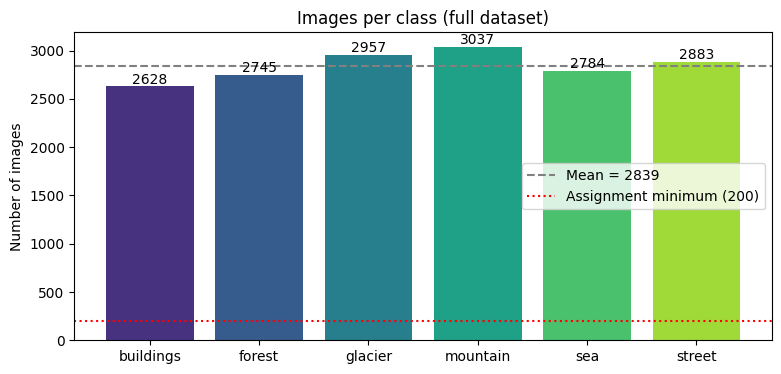

Imbalance ratio (largest / smallest): 1.16


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(counts_df.index, counts_df["images"],
              color=sns.color_palette("viridis", len(counts_df)))
ax.bar_label(bars)
ax.axhline(counts_df["images"].mean(), linestyle="--", color="gray",
           label=f"Mean = {counts_df['images'].mean():.0f}")
ax.axhline(200, linestyle=":", color="red", label="Assignment minimum (200)")
ax.set_title("Images per class (full dataset)")
ax.set_ylabel("Number of images")
ax.legend()
plt.show()

ratio = counts_df["images"].max() / counts_df["images"].min()
print(f"Imbalance ratio (largest / smallest): {ratio:.2f}")

### 3.2 Sample grid
Display a random 5×5 grid of training images with their labels to check image quality and spot ambiguous labels. This is written as a function because the same pattern is reused later for misclassified images.

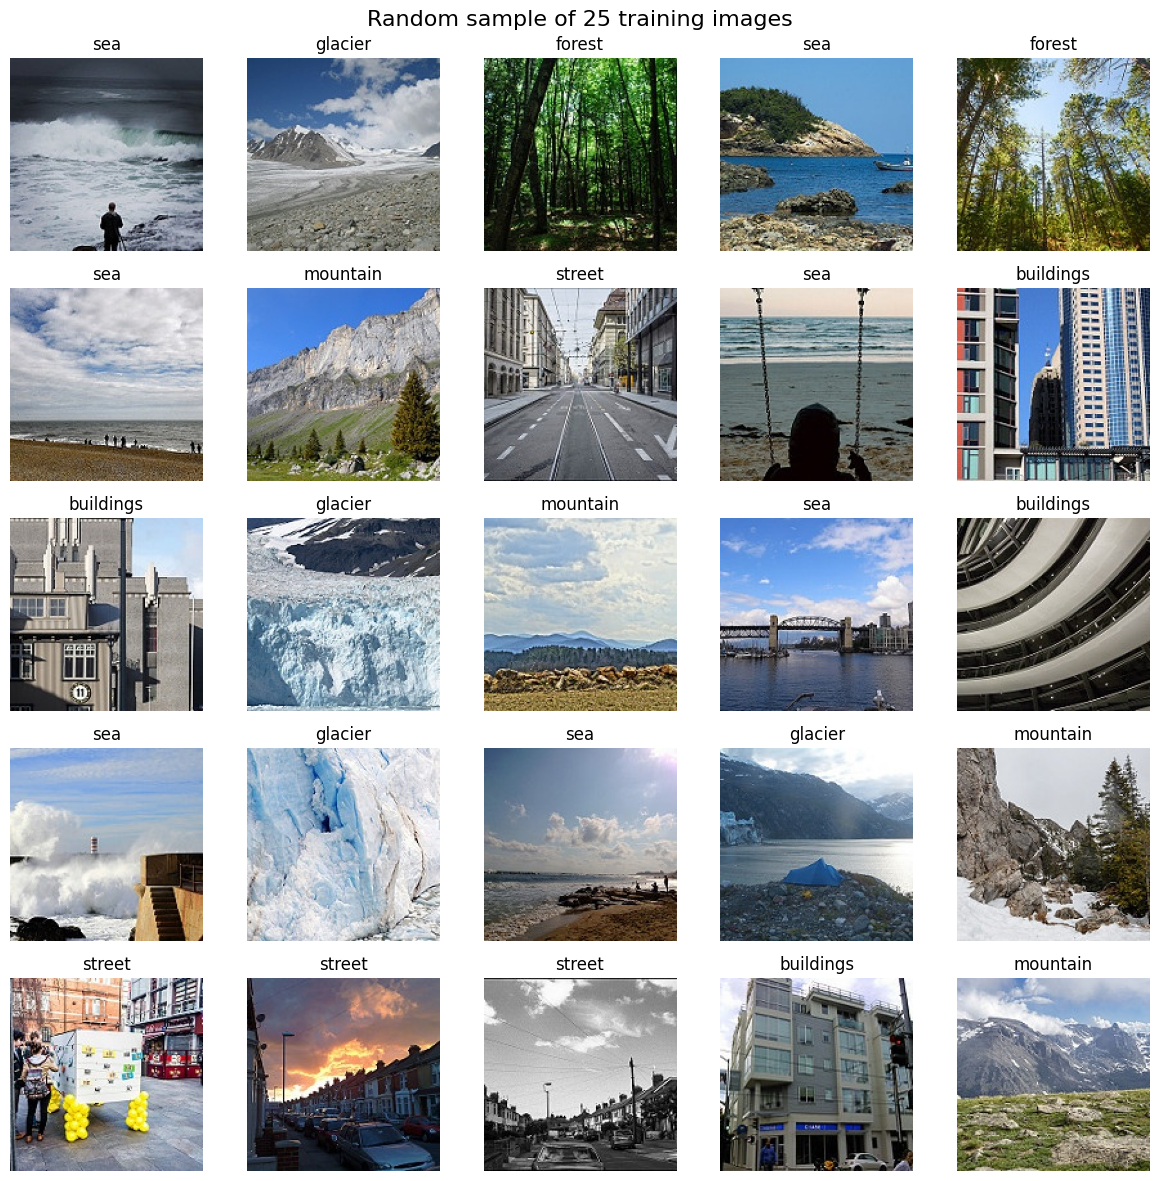

In [6]:
def show_sample_grid(image_root, class_names, n_rows=5, n_cols=5, seed=SEED):
    """Display a random grid of images with their class labels."""
    rng = np.random.default_rng(seed)
    all_images = [(p, cls) for cls in class_names
                  for p in (image_root / cls).glob("*.jpg")]
    picks = rng.choice(len(all_images), size=n_rows * n_cols, replace=False)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 12))
    for ax, idx in zip(axes.flat, picks):
        path, cls = all_images[idx]
        ax.imshow(Image.open(path))
        ax.set_title(cls)
        ax.axis("off")
    plt.suptitle("Random sample of 25 training images", fontsize=16)
    plt.tight_layout()
    plt.show()

class_names = sorted(counts_df.index)
show_sample_grid(raw_path / "seg_train/seg_train", class_names)

### Prediction from the sample grid
Before training anything, I predict that **glacier vs mountain** will be the most confused pair, followed by **buildings vs street**:

- **Glacier vs mountain:** both are made of the same things (snow, ice, rock and sky), and a glacier usually sits within mountains, so most glacier photos contain mountains and many mountain photos contain snow. Their layouts also match: sky on top, white or grey terrain below. The grid already shows overlapping labels: one image labelled *glacier* looks like a snowy mountain valley, which even a human could label either way.
- **Buildings vs street:** a street photo is mostly buildings on both sides, and a buildings photo often has a road at the bottom. The colours are the same (grey, concrete, glass); the difference is mainly the viewpoint (looking down a road vs up at a facade), which is subtler than colour or texture.
- **Forest** should be the easiest class: dense green texture, almost no sky, and nothing like it in the other classes.

### 3.3 Average image and colour profile per class
Load 200 random training images per class once (resized to 150×150, because a few images in the dataset are not exactly that size), then reuse them for two views: the **average image** per class and the **RGB colour histograms** per class.

In [7]:
def load_class_images(image_root, cls, n=200, size=(150, 150), seed=SEED):
    """Load n random images of one class as a float array of shape (n, H, W, 3)."""
    rng = np.random.default_rng(seed)
    paths = sorted((image_root / cls).glob("*.jpg"))
    picks = rng.choice(len(paths), size=n, replace=False)
    return np.stack([
        np.asarray(Image.open(paths[i]).convert("RGB").resize(size), dtype=np.float32)
        for i in picks
    ])

train_root = raw_path / "seg_train/seg_train"
class_samples = {cls: load_class_images(train_root, cls) for cls in class_names}
print({cls: arr.shape for cls, arr in class_samples.items()})

{'buildings': (200, 150, 150, 3), 'forest': (200, 150, 150, 3), 'glacier': (200, 150, 150, 3), 'mountain': (200, 150, 150, 3), 'sea': (200, 150, 150, 3), 'street': (200, 150, 150, 3)}


**Average image per class:** averaging 200 images pixel by pixel blurs out individual details and leaves only each class's typical layout. Classes with similar averages are likely to be harder to separate.

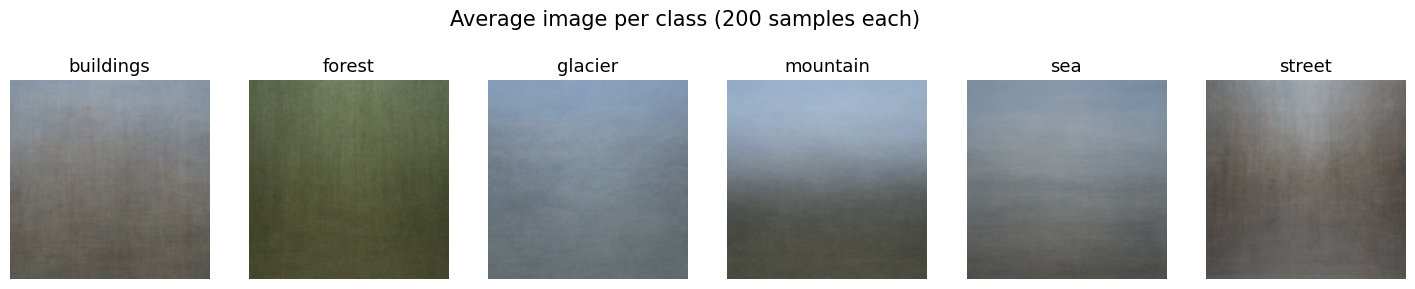

In [8]:
fig, axes = plt.subplots(1, len(class_names), figsize=(18, 3.5))
for ax, cls in zip(axes, class_names):
    mean_img = class_samples[cls].mean(axis=0)   # average over the 200 images
    ax.imshow(mean_img.astype("uint8"))
    ax.set_title(cls, fontsize=13)
    ax.axis("off")
plt.suptitle("Average image per class (200 samples each)", fontsize=15)
plt.show()

**Colour histograms:** the distribution of red, green and blue pixel intensities for each class, drawn on shared axes so the classes can be compared fairly.

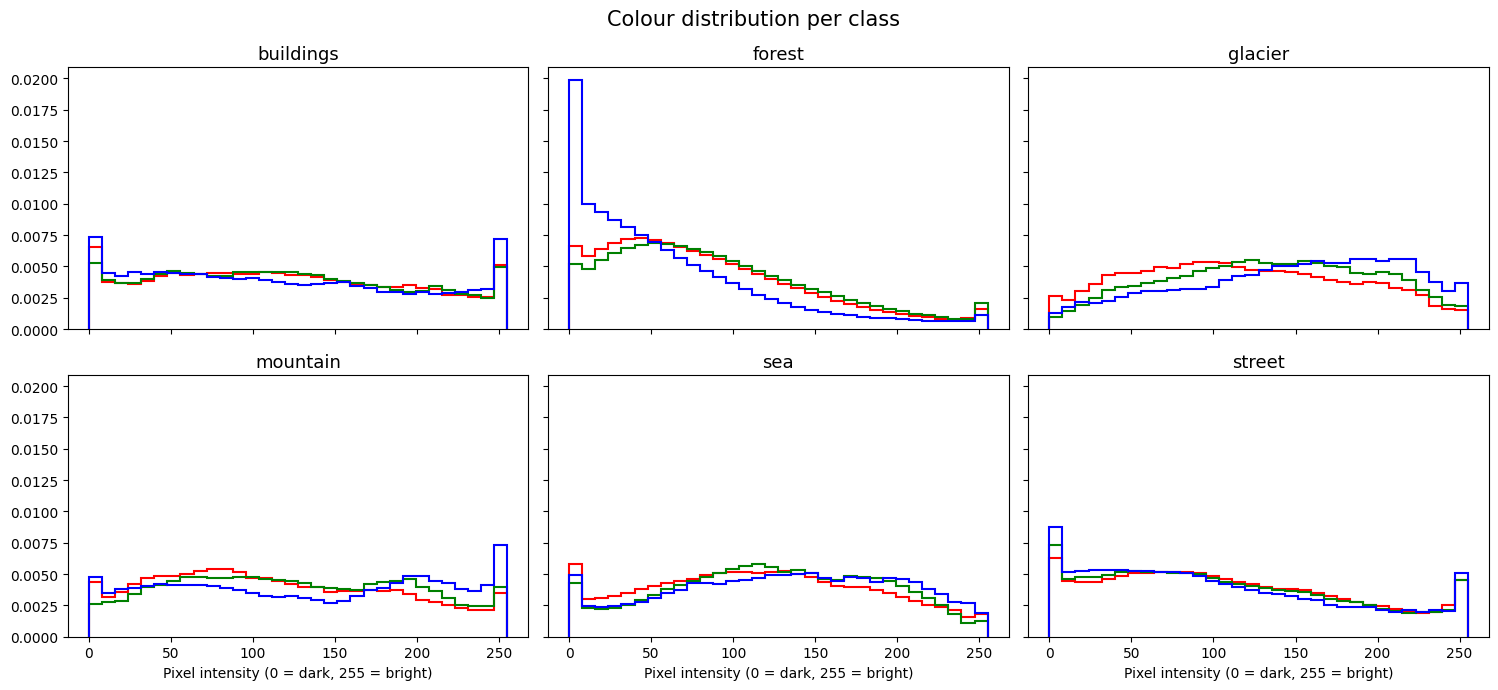

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, cls in zip(axes.flat, class_names):
    for ch, colour in enumerate(["red", "green", "blue"]):
        ax.hist(class_samples[cls][..., ch].ravel(), bins=32, range=(0, 255),
                histtype="step", color=colour, density=True, linewidth=1.5)
    ax.set_title(cls, fontsize=13)
for ax in axes[-1]:
    ax.set_xlabel("Pixel intensity (0 = dark, 255 = bright)")
plt.suptitle("Colour distribution per class", fontsize=15)
plt.tight_layout()
plt.show()

### What the average images and histograms show
**Average images**
- **Street** shows a faint V-shape: a bright sky wedge at the top centre with darker sides where buildings line the road. The road's perspective survives the averaging.
- **Mountain** has a clear horizon: bright sky on top and darker ground in the bottom half.
- **Glacier** is almost uniformly pale blue-white, with no strong horizon.
- **Glacier and sea** look the most alike: both are pale, bluish and featureless.
- **Buildings and street** share the same grey-brown tone.

**Colour histograms**
- **Forest** is the most distinctive: dark overall, with blue heavily skewed towards 0 (almost no sky, and vegetation absorbs blue light).
- **Glacier** is shifted towards bright values, with blue dominant at high intensities (white-blue ice).
- **Buildings and street** are nearly identical: flat profiles with spikes at 0 and 255 (deep shadows and blown-out sky).
- **Mountain and sea** both show soft mid-tone humps.

**Interpretation.** Glacier and mountain are *less* similar on average than I predicted, because mountain has a dark lower half. This does not rule out my prediction: averages only capture overall layout, while a CNN relies on local textures (snow, rock, ice), which these two classes share. Colour alone could separate forest and glacier, but buildings and street have almost the same colour profile, so the model must recognise **structure and shape** (a road receding into the distance vs a facade). This is exactly what pretrained CNN features provide, and why transfer learning is a better choice than a simple colour-based classifier.

### Exploratory Analysis – Findings

**Class balance.** The full dataset contains 17,034 images across 6 classes, ranging from 2,628 (buildings) to 3,037 (mountain). The imbalance ratio is 1.16, which is mild: no class is large enough for the model to score well by simply favouring it. Since I sample exactly 1,000 images per class for training, the working dataset is perfectly balanced, so no class weighting or oversampling is needed.

**Sample images.** The 5×5 grid shows that the classes are mostly clear, but some labels are genuinely ambiguous. For example, one image labelled *glacier* looks like a snowy mountain valley, and one labelled *sea* contains a bridge and city skyline. A few errors on images like these are expected and may reflect label ambiguity rather than model failure.

**Average images and colour profiles.** Averaging 200 images per class reveals each class's typical layout: *mountain* shows a clear horizon (bright sky over darker ground), *street* shows a faint V-shape from road perspective, and *forest* is uniformly dark green. The colour histograms show that *forest* (dark, low blue) and *glacier* (bright, blue-dominant) have distinctive colour signatures, while *buildings* and *street* have almost identical colour profiles. This means colour alone cannot separate the urban classes: the model must learn structural features such as road perspective versus building facades, which is exactly what pretrained CNN features provide.

**Prediction.** I expect the most confusion between **glacier and mountain** (shared snow, rock and sky textures, and visibly overlapping labels) and between **buildings and street** (near-identical colours, with buildings appearing in most street photos). I expect *forest* to be the easiest class. I will check these predictions against the confusion matrix in Section 9.

## 4. Train / Validation / Test Split
The original dataset ships with its own train and test folders, but the assignment requires a 70/15/15 split, so both folders are pooled and re-split:
- For each class, **1,000 images** are sampled (well above the 200 minimum, while keeping training time manageable on a free Colab GPU) and split **700 / 150 / 150**. Splitting per class (**stratified**) gives every split exactly the same class balance.
- Images are physically copied into `data/train`, `data/val` and `data/test`. Splitting at the **file level**, with a sorted file list and a fixed seed, makes the split reproducible and guarantees that no image appears in more than one split.
- This avoids a problem in the class notebook, where validation and test sets were created with `take()`/`skip()` on a dataset that reshuffles on every pass, so images could move between validation and test.

In [10]:
import shutil

def build_split_folders(source_roots, dest_root, class_names, n_per_class, splits, seed=SEED):
    """Pool images, sample n_per_class per class, and copy them into
    dest_root/{train,val,test}/{class}/ using a stratified split."""
    rng = np.random.default_rng(seed)
    if dest_root.exists():
        shutil.rmtree(dest_root)              # start fresh so re-runs are identical

    n_train = int(splits[0] * n_per_class)
    n_val = int(splits[1] * n_per_class)
    summary = {}

    for cls in class_names:
        paths = sorted(p for root in source_roots for p in (root / cls).glob("*.jpg"))
        idx = rng.choice(len(paths), size=n_per_class, replace=False)
        chosen = [paths[i] for i in idx]

        parts = {
            "train": chosen[:n_train],
            "val":   chosen[n_train:n_train + n_val],
            "test":  chosen[n_train + n_val:],
        }
        for split, files in parts.items():
            out_dir = dest_root / split / cls
            out_dir.mkdir(parents=True, exist_ok=True)
            for i, f in enumerate(files):
                shutil.copy(f, out_dir / f"{cls}_{i:04d}.jpg")
        summary[cls] = {split: len(files) for split, files in parts.items()}

    return pd.DataFrame(summary).T

source_roots = [raw_path / s for s in source_splits]
split_summary = build_split_folders(source_roots, DATA_DIR, class_names,
                                    IMAGES_PER_CLASS, SPLITS)
print(split_summary)
print("\nTotals:", split_summary.sum().to_dict())

           train  val  test
buildings    700  150   150
forest       700  150   150
glacier      700  150   150
mountain     700  150   150
sea          700  150   150
street       700  150   150

Totals: {'train': 4200, 'val': 900, 'test': 900}


**Why split before anything else:** the test set has to simulate brand-new photos the model has never seen. If an image appeared in both train and test, the model could simply remember it, and the test score would measure memory instead of real ability, like giving students the exam questions as homework.

## 5. Data Pipeline & Augmentation
Load each split as a `tf.data` dataset, verify the pipeline, define the augmentation layers, and check the input normalisation expected by MobileNetV2.

### 5.1 Loading the splits
`image_dataset_from_directory` turns each split folder into batches of 32 images, resized from 150×150 to MobileNetV2's 224×224 input, with integer labels in alphabetical folder order. Only the training set is shuffled; validation and test keep a fixed order so predictions can be matched to their labels later. `prefetch` lets the CPU prepare the next batch while the GPU trains on the current one. (Caching was removed after it caused a silent bug; see the debugging note in Section 7.)

In [11]:
def make_dataset(split, shuffle):
    """Load one split folder as a batched tf.data.Dataset."""
    return tf.keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        label_mode="int",
    )

train_ds = make_dataset("train", shuffle=True)
val_ds   = make_dataset("val",   shuffle=False)
test_ds  = make_dataset("test",  shuffle=False)

assert train_ds.class_names == class_names, "Class order mismatch!"

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 4200 files belonging to 6 classes.
Found 900 files belonging to 6 classes.
Found 900 files belonging to 6 classes.


### 5.2 Pipeline sanity check
Count the batches the training set actually yields per epoch (4,200 / 32, rounded up, = 132). This assertion was added after a bug silently truncated the training set to a single batch; it makes any future truncation fail loudly.

In [12]:
n_train_batches = sum(1 for _ in train_ds)
print(f"Training batches per epoch: {n_train_batches}  (expected {int(np.ceil(4200 / BATCH_SIZE))})")
assert n_train_batches == int(np.ceil(4200 / BATCH_SIZE)), "Training set is truncated!"

Training batches per epoch: 132  (expected 132)


### 5.3 Augmentation pipeline
Four random transformations (horizontal flip, small rotation, zoom and brightness), active only during training. Below, the pipeline is applied nine times to one training image to show the variety it produces. The reasoning for each choice follows the normalisation check.

In [13]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomBrightness(0.2),
], name="data_augmentation")

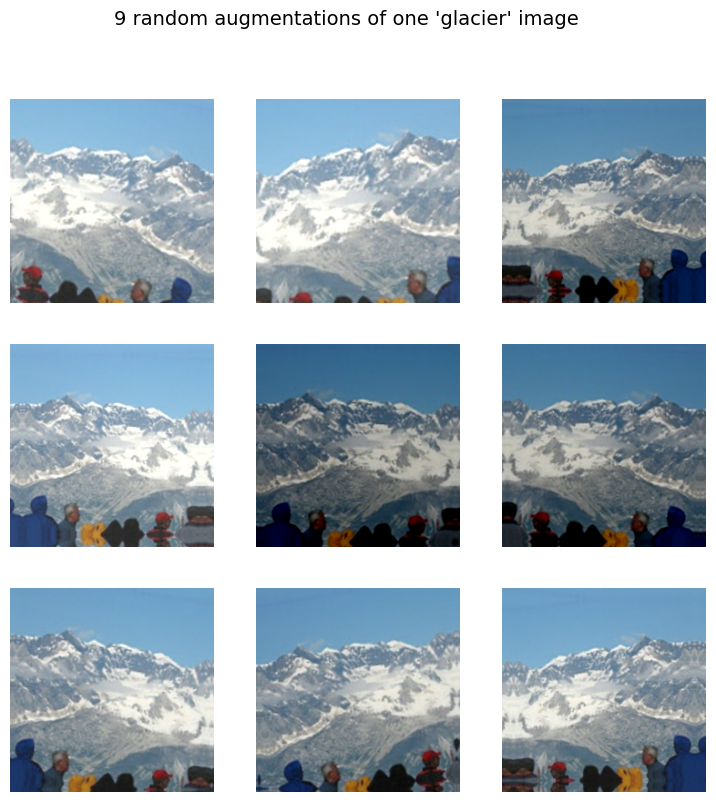

In [14]:
def show_augmentations(dataset, augmenter, n=9):
    """Apply the augmentation pipeline repeatedly to one image and display the results."""
    images, labels = next(iter(dataset))
    image = tf.expand_dims(images[0], 0)          # add a batch dimension: (1, 224, 224, 3)

    plt.figure(figsize=(9, 9))
    for i in range(n):
        augmented = augmenter(image, training=True)[0]
        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.clip_by_value(augmented, 0, 255).numpy().astype("uint8"))
        plt.axis("off")
    plt.suptitle(f"9 random augmentations of one '{class_names[labels[0]]}' image", fontsize=14)
    plt.show()

show_augmentations(train_ds, data_augmentation)

### 5.4 Normalisation check
MobileNetV2 was pretrained on pixels scaled to [-1, 1], and `preprocess_input` performs this scaling (`x / 127.5 - 1`). This check verifies the conversion on one batch.

In [15]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

images, _ = next(iter(train_ds))
scaled = preprocess_input(images)
print(f"Raw pixels:             min={images.numpy().min():.1f}, max={images.numpy().max():.1f}")
print(f"After preprocess_input: min={scaled.numpy().min():.2f}, max={scaled.numpy().max():.2f}")

Raw pixels:             min=0.0, max=255.0
After preprocess_input: min=-1.00, max=1.00


### Augmentation choices
Augmentation is applied only during training, so the model sees a slightly different version of each image every epoch and learns general scene features instead of memorising specific photos. Every transformation was chosen to produce a *realistic* photo of the same class:

- **Horizontal flip:** natural and urban scenes have no left/right meaning, so a mirrored scene is still a valid example of its class.
- **Small rotation (±11°):** simulates a slightly tilted camera. Larger rotations would tilt horizons unrealistically and fill large corners with mirrored pixels (visible at the edges of the augmented samples above).
- **Zoom (±15%):** simulates the same scene photographed from closer or further away.
- **Brightness (±20%):** simulates different times of day, weather and exposure, which is important for glacier, sea and mountain, whose colours depend heavily on lighting.
- **Vertical flip was deliberately not used:** real photos are always taken right-side up, so an upside-down scene would never appear at test time. The average images show that "sky on top" is a strong and consistent cue for this dataset: *mountain* has a bright sky above darker ground, and *street* shows a bright sky wedge above the road. Flipping vertically would teach the model that sky can be at the bottom, destroying a useful feature. For example, an upside-down building, with its dome pointing down and sky below it, is not a realistic example of the *buildings* class.

**Normalisation:** MobileNetV2 was pretrained on inputs scaled to [-1, 1], so `preprocess_input` is applied inside the model. The check above confirms pixels are mapped from 0–255 to -1–1.

# Part 2 — Transfer Learning (Frozen Base)

## 6. Model: Frozen MobileNetV2 Base
Compare the four allowed architectures, load MobileNetV2 without its classification layer, freeze it, and attach a custom classification head.

### 6.1 Architecture comparison
Parameter counts are measured by building each allowed architecture with `weights=None` (architecture only, no weight download); ImageNet top-1 accuracy comes from the official Keras applications table. The x-axis is logarithmic because VGG16 is roughly 40× larger than MobileNetV2.

                Params (M)  ImageNet top-1 (%)
Model                                         
VGG16                138.4                71.3
ResNet50              25.6                74.9
MobileNetV2            3.5                71.3
EfficientNetB0         5.3                77.1


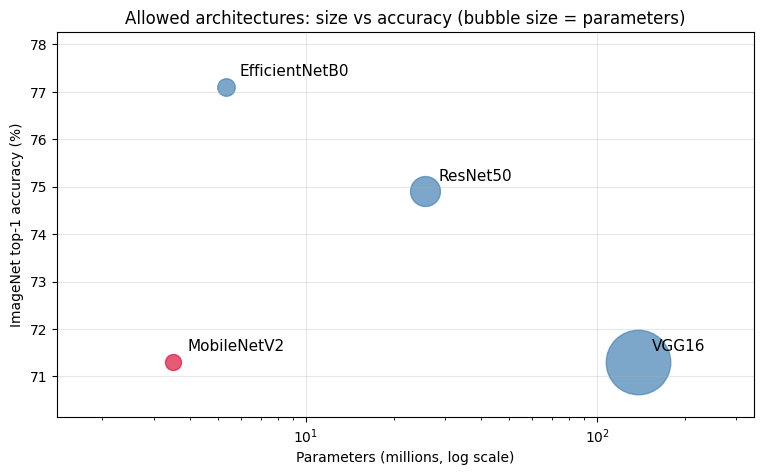

In [16]:
# ImageNet top-1 accuracy from the official Keras applications table (keras.io/api/applications)
architectures = {
    "VGG16":          (tf.keras.applications.VGG16,          71.3),
    "ResNet50":       (tf.keras.applications.ResNet50,       74.9),
    "MobileNetV2":    (tf.keras.applications.MobileNetV2,    71.3),
    "EfficientNetB0": (tf.keras.applications.EfficientNetB0, 77.1),
}

rows = []
for name, (constructor, top1) in architectures.items():
    m = constructor(weights=None)                 # architecture only, no weight download
    rows.append({"Model": name, "Params (M)": m.count_params() / 1e6, "ImageNet top-1 (%)": top1})
    del m
arch_df = pd.DataFrame(rows).set_index("Model").round(1)
print(arch_df)

fig, ax = plt.subplots(figsize=(9, 5))
for name, row in arch_df.iterrows():
    colour = "crimson" if name == "MobileNetV2" else "steelblue"
    ax.scatter(row["Params (M)"], row["ImageNet top-1 (%)"],
               s=row["Params (M)"] * 15 + 80, color=colour, alpha=0.7)
    ax.annotate(name, (row["Params (M)"], row["ImageNet top-1 (%)"]),
                textcoords="offset points", xytext=(10, 8), fontsize=11)
ax.set_xscale("log")
ax.set_xlabel("Parameters (millions, log scale)")
ax.set_ylabel("ImageNet top-1 accuracy (%)")
ax.set_title("Allowed architectures: size vs accuracy (bubble size = parameters)")
ax.grid(alpha=0.3)
ax.margins(x=0.25, y=0.2)
plt.show()

### Why MobileNetV2?
I compared the four allowed architectures by parameter count and ImageNet top-1 accuracy (chart above). VGG16 has ~138M parameters, roughly 40× more than MobileNetV2 (~3.5M), yet both reach the same 71.3% ImageNet accuracy, so VGG16's extra size buys nothing for this task. ResNet50 (~25.6M) and EfficientNetB0 (~5.3M) are more accurate on ImageNet (74.9% and 77.1%), but they are larger and deeper, which makes each training epoch slower.

I chose MobileNetV2 for three reasons:
1. **Dataset size:** with only 4,200 training images, a smaller model has fewer weights to adapt during fine-tuning, which lowers the risk of overfitting.
2. **Speed:** it trains quickly on a free Colab GPU, so I can run and compare several experiments within one session.
3. **Familiarity:** it is the architecture used in class, so its preprocessing (`[-1, 1]` scaling) and layer structure are well understood.

The trade-off is a few points of ImageNet accuracy compared with EfficientNetB0. Since the six scene classes are far simpler than ImageNet's 1,000, I expect MobileNetV2's features to be more than sufficient, and this assumption is tested by the frozen-base results below.

### 6.2 Load the base and freeze it
`include_top=False` removes MobileNetV2's 1,000-class ImageNet layer and keeps the feature extractor, which turns a 224×224 image into a 7×7×1,280 feature map. Setting `trainable = False` freezes all of its weights. This matters because the new head starts with random weights: its early errors are large, and if they flowed back through an unfrozen base they would damage the pretrained features before the head learned anything. The parameter count below confirms the base is frozen (0 trainable parameters).

In [17]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

def count_params(model, label=""):
    """Print and return trainable vs non-trainable parameter counts."""
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    frozen = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    print(f"{label:<20} trainable: {trainable:>10,} | non-trainable: {frozen:>10,} | total: {trainable + frozen:>10,}")
    return trainable, frozen

count_params(base_model, "Base model (frozen)")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model (frozen)  trainable:          0 | non-trainable:  2,257,984 | total:  2,257,984


(0, 2257984)

### 6.3 Custom classification head
The full model is:

`image → augmentation → preprocess (-1…1) → MobileNetV2 (frozen) → GlobalAveragePooling2D → Dropout(0.3) → Dense(128, ReLU) → Dropout(0.3) → Dense(6, softmax)`

- **GlobalAveragePooling2D** reduces the 7×7×1,280 feature map to 1,280 values (one per feature detector) with zero parameters. It asks "how strongly does each feature appear anywhere in the image", and is far less prone to overfitting than `Flatten` (which would give 62,720 inputs).
- **Dropout (0.3)** before and after the hidden layer stops the head from relying on a few features, which matters with only 4,200 training images.
- **Dense(128, ReLU)** lets the head *combine* features (e.g. snow + sky + rock texture → mountain) rather than only weighting them individually.
- **Dense(6, softmax)** outputs one probability per class.
- The base is called with `training=False`, which keeps its BatchNormalization layers in inference mode, even after unfreezing in Part 3, so their ImageNet statistics are not overwritten by small training batches.

The summary confirms that only the head is trainable: **164,742 of 2,422,726 parameters (~7%)**.

In [18]:
def build_model(base_model, num_classes, dense_units=128, dropout=0.3):
    """Attach augmentation, preprocessing and a classification head to a pretrained base."""
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = base_model(x, training=False)          # keep BatchNorm in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(dense_units, activation="relu")(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="mobilenetv2_scene_classifier")

model = build_model(base_model, num_classes=len(class_names))
model.summary()
frozen_trainable, frozen_nontrainable = count_params(model, "Full model (frozen)")

Model: "mobilenetv2_scene_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Full model (frozen)  trainable:    164,742 | non-trainable:  2,257,984 | total:  2,422,726


## 7. Train the Frozen Model
Only the head is trained (base frozen) for 20 epochs with Adam (learning rate 1e-3, a standard rate for new, randomly initialised layers). Early stopping is not used so that the full 20 epochs required by the brief are completed. A `ModelCheckpoint` saves the weights from the epoch with the best validation accuracy; Part 3 fine-tuning continues from this checkpoint.

In [19]:
FROZEN_EPOCHS = 20
FROZEN_LR = 1e-3
FROZEN_CKPT = "frozen_best.weights.h5"

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FROZEN_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    FROZEN_CKPT, monitor="val_accuracy", save_best_only=True, save_weights_only=True,
)

history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FROZEN_EPOCHS,
    callbacks=[checkpoint],
)

Epoch 1/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 23s 98ms/step - accuracy: 0.7929 - loss: 0.5390 - val_accuracy: 0.8878 - val_loss: 0.2834
Epoch 2/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.8781 - loss: 0.3540 - val_accuracy: 0.8878 - val_loss: 0.2858
Epoch 3/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.8848 - loss: 0.3061 - val_accuracy: 0.8889 - val_loss: 0.2951
Epoch 4/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.8810 - loss: 0.3031 - val_accuracy: 0.8867 - val_loss: 0.2729
Epoch 5/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.8900 - loss: 0.2846 - val_accuracy: 0.8933 - val_loss: 0.2623
Epoch 6/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.8995 - loss: 0.2650 - val_accuracy: 0.8944 - val_loss: 0.2650
Epoch 7/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.9038 - loss: 0.2489 - val_accuracy: 0.8922 - val_loss: 0.2774
Epoch 8/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.9069 - loss: 0.2454 - val

### 7.1 Training curves
Plot training vs validation accuracy and loss with a reusable function (also used for fine-tuning), and record the best frozen-base validation accuracy for the comparison in Part 3.

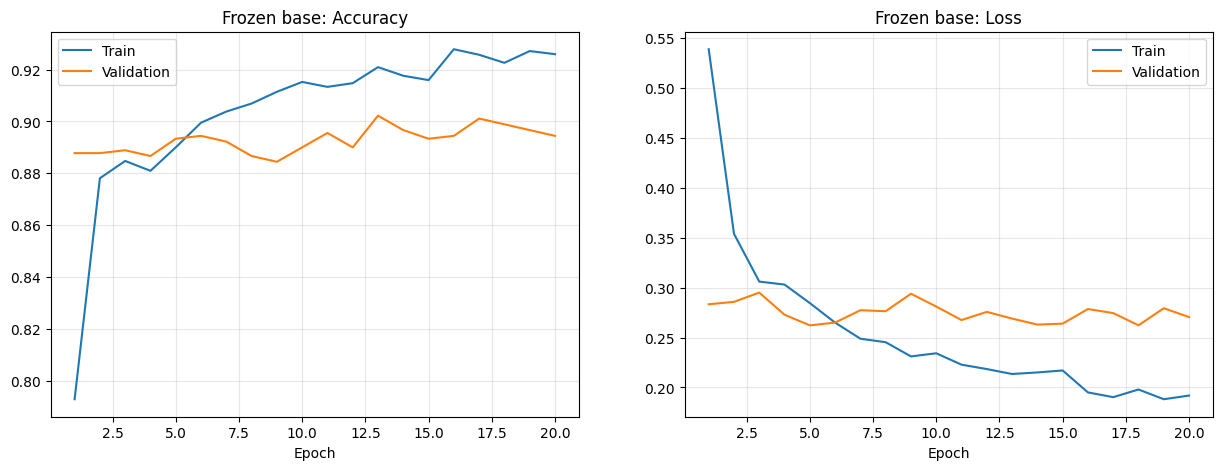

Best frozen-base validation accuracy: 0.9022 (epoch 13), val loss 0.2691


In [20]:
def plot_history(history, title, start_epoch=0):
    """Plot training vs validation accuracy and loss from a Keras History object."""
    hist = pd.DataFrame(history.history)
    epochs = np.arange(start_epoch + 1, start_epoch + len(hist) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    ax1.plot(epochs, hist["accuracy"], label="Train")
    ax1.plot(epochs, hist["val_accuracy"], label="Validation")
    ax1.set_title(f"{title}: Accuracy"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, hist["loss"], label="Train")
    ax2.plot(epochs, hist["val_loss"], label="Validation")
    ax2.set_title(f"{title}: Loss"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(alpha=0.3)
    plt.show()
    return hist

hist_frozen = plot_history(history_frozen, "Frozen base")

best_epoch = hist_frozen["val_accuracy"].idxmax()
best_frozen_val_acc = hist_frozen["val_accuracy"].max()
best_frozen_val_loss = hist_frozen.loc[best_epoch, "val_loss"]
print(f"Best frozen-base validation accuracy: {best_frozen_val_acc:.4f} (epoch {best_epoch + 1}), "
      f"val loss {best_frozen_val_loss:.4f}")

### Frozen-base training: interpretation
- **Fast convergence:** validation accuracy was already **0.888 after the first epoch** and stayed between 0.884 and 0.902 for all 20 epochs. The best value was **0.9022 at epoch 13** (validation loss 0.2691). The pretrained features are so informative that the head learns to use them almost immediately.
- **No underfitting:** training accuracy rose from 0.79 to about 0.93, and training loss fell steadily throughout.
- **Mild overfitting:** from around epoch 6, training accuracy moved above validation accuracy and ended about 3 points higher (0.926 vs 0.894), while validation loss stopped improving and fluctuated between 0.26 and 0.29. The gap stays small because only the 165k-parameter head can learn, and dropout and augmentation regularise it.
- **Conclusion:** the frozen model converged within about 10 epochs. Further improvement requires the base itself to adapt, which motivates fine-tuning.

**Debugging note:** my first training run reported 80% validation accuracy and looked plausible, but training accuracy only changed in steps of 1/32 (e.g. 0.1562 = 5/32, 0.6562 = 21/32), and Keras warned that the input "ran out of data". Each epoch was training on a **single batch of 32 images**: the training set had been wrapped in `.cache()`, and earlier `next(iter(...))` calls (for the augmentation and normalisation checks) read only one batch, leaving a truncated cache. I removed the cache, added the batch-count assertion in Section 5.2, and retrained. The results above come from the corrected pipeline.

# Part 3 — Fine-Tuning

## 8. Fine-Tuning
Reload the best frozen-base checkpoint and record its validation and test metrics as the baseline, then unfreeze the top layers of MobileNetV2 and continue training the same model (no re-initialisation) with a much smaller learning rate and a cosine learning-rate schedule.

In [21]:
model.load_weights(FROZEN_CKPT)    # best frozen epoch, not the last one

frozen_val_loss, frozen_val_acc = model.evaluate(val_ds, verbose=0)
frozen_test_loss, frozen_test_acc = model.evaluate(test_ds, verbose=0)
print(f"Frozen baseline | val acc {frozen_val_acc:.4f} | val loss {frozen_val_loss:.4f} | test acc {frozen_test_acc:.4f}")

Frozen baseline | val acc 0.9022 | val loss 0.2691 | test acc 0.9122


### 8.1 Unfreezing strategy
CNN layers go from generic to specific. Early layers detect edges, colours and simple textures that are useful for any photograph, so they stay frozen. Later layers encode ImageNet-specific concepts (animal faces, object parts) and benefit most from adapting to scene imagery. I unfroze **from layer 100 (`block_11_expand_relu`) onward: 54 of 154 layers, roughly the last third**. This is more than the 120 used in class, because natural scenes differ more from ImageNet's object-centred photos than food does, but not the whole network, because 4,200 images is too few to safely update all 2.2M base weights. The counts below show trainable parameters increasing from **164,742 to 2,026,182 (12.3×)**.

In [22]:
print("Layers in base model:", len(base_model.layers))

FINE_TUNE_AT = 100
base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

print(f"Unfreezing from layer {FINE_TUNE_AT} ('{base_model.layers[FINE_TUNE_AT].name}') "
      f"→ {len(base_model.layers) - FINE_TUNE_AT} layers trainable")

ft_trainable, ft_nontrainable = count_params(model, "After unfreezing")
print(f"Trainable parameters: {frozen_trainable:,} → {ft_trainable:,} "
      f"({ft_trainable / frozen_trainable:.1f}× more)")

Layers in base model: 154
Unfreezing from layer 100 ('block_11_expand_relu') → 54 layers trainable
After unfreezing     trainable:  2,026,182 | non-trainable:    396,544 | total:  2,422,726
Trainable parameters: 164,742 → 2,026,182 (12.3× more)


### 8.2 Learning rate, schedule and recompiling
- **Learning rate 1e-5 (100× smaller than 1e-3):** the unfrozen layers already contain good features. A large learning rate would take big steps and overwrite them (*catastrophic forgetting*), especially early on when the errors are still large; a small one only nudges them towards the new task. At 1e-3, I would expect validation accuracy to drop sharply at the start of fine-tuning, possibly below the frozen baseline, followed by unstable curves.
- **Cosine decay schedule:** the learning rate starts at 1e-5 and decreases smoothly towards 0 over the 15 epochs (15 × 132 steps): larger steps early, very gentle steps near the end when the model is close to its best. I chose it over `ReduceLROnPlateau` because it changes the rate every step in a predictable way, so the schedule is guaranteed to be visible in the learning-rate plot. A callback logs the actual learning rate after every epoch.
- **Recompiling:** `compile()` fixes which weights the optimizer updates. Changing `trainable` afterwards has no effect until the model is recompiled; without it, the optimizer would keep updating only the head. Recompiling also installs the new optimizer with the small learning rate and the schedule.
- `initial_epoch=20` continues the epoch numbering from Part 2, showing this is the same model continuing training, not a fresh start.

In [23]:
FINE_TUNE_EPOCHS = 15
FINE_TUNE_LR = FROZEN_LR / 100           # 1e-3 → 1e-5
FINETUNE_CKPT = "finetuned_best.weights.h5"

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=FINE_TUNE_LR,
    decay_steps=FINE_TUNE_EPOCHS * n_train_batches,
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

lr_log = []
lr_logger = tf.keras.callbacks.LambdaCallback(
    on_epoch_end=lambda epoch, logs: lr_log.append(float(model.optimizer.learning_rate))
)
ft_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    FINETUNE_CKPT, monitor="val_accuracy", save_best_only=True, save_weights_only=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FROZEN_EPOCHS + FINE_TUNE_EPOCHS,
    initial_epoch=FROZEN_EPOCHS,
    callbacks=[lr_logger, ft_checkpoint],
)

Epoch 21/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 30s 125ms/step - accuracy: 0.7867 - loss: 0.6582 - val_accuracy: 0.8989 - val_loss: 0.2795
Epoch 22/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.8505 - loss: 0.4210 - val_accuracy: 0.8989 - val_loss: 0.2852
Epoch 23/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.8702 - loss: 0.3704 - val_accuracy: 0.8944 - val_loss: 0.2892
Epoch 24/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - accuracy: 0.8757 - loss: 0.3265 - val_accuracy: 0.8978 - val_loss: 0.2905
Epoch 25/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - accuracy: 0.8883 - loss: 0.3031 - val_accuracy: 0.8978 - val_loss: 0.2937
Epoch 26/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 116ms/step - accuracy: 0.8819 - loss: 0.3229 - val_accuracy: 0.8989 - val_loss: 0.2995
Epoch 27/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - accuracy: 0.9000 - loss: 0.2725 - val_accuracy: 0.8989 - val_loss: 0.3018
Epoch 28/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 116ms/step - accuracy: 0.8960 -

Plot the fine-tuning curves (epochs 21–35) and the logged learning rate.

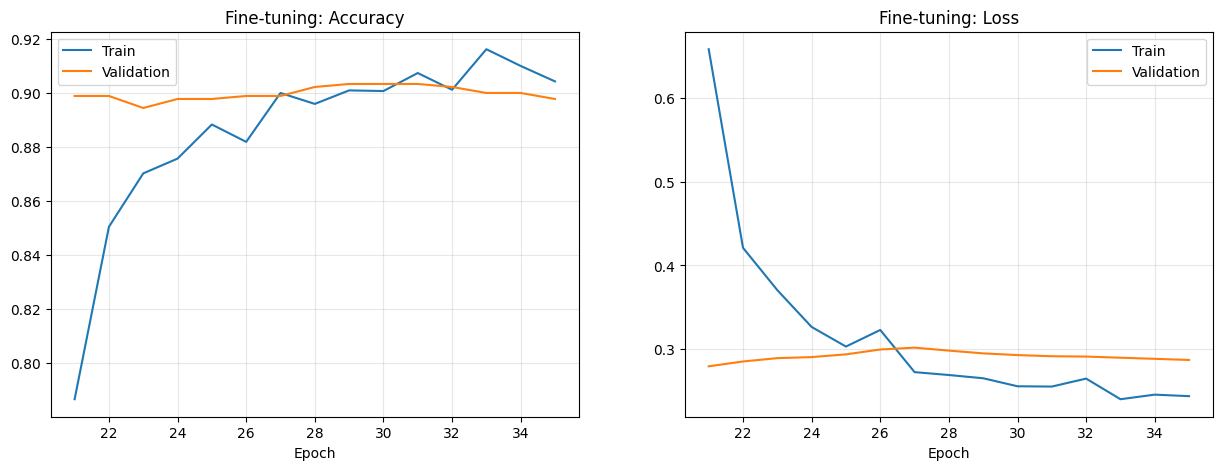

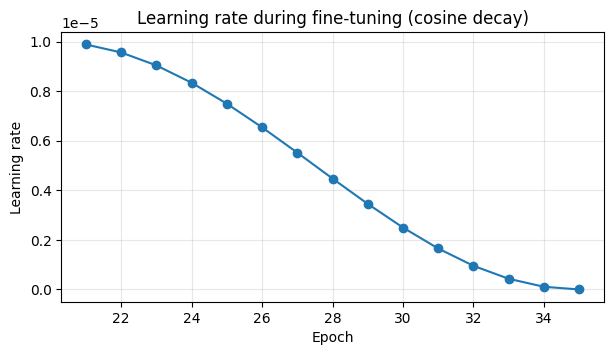

In [24]:
hist_ft = plot_history(history_ft, "Fine-tuning", start_epoch=FROZEN_EPOCHS)

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(FROZEN_EPOCHS + 1, FROZEN_EPOCHS + len(lr_log) + 1), lr_log, marker="o")
plt.title("Learning rate during fine-tuning (cosine decay)")
plt.xlabel("Epoch"); plt.ylabel("Learning rate"); plt.grid(alpha=0.3)
plt.show()

### Fine-tuning round 1: interpretation
- **An initial shock, then recovery:** in the first fine-tuning epoch, training accuracy dropped from 0.926 (end of frozen training) to 0.787, and training loss jumped from 0.19 to 0.66. Unfreezing 54 layers changes the features the head had been trained on, so the head briefly has to re-adapt. Training accuracy recovered to about 0.90–0.92 by the end of the round.
- **Validation stayed stable:** validation accuracy remained at about 0.90 throughout (0.894–0.903), so the small learning rate prevented any real damage to the pretrained features.
- **The schedule stabilised training:** validation loss rose slightly in the first epochs (0.280 → 0.302 at epoch 27), then fell again (0.287 at epoch 35) as cosine decay reduced the learning rate.
- **Small gain:** the best round-1 validation accuracy was 0.9033, only marginally above the frozen best (0.9022).
- The learning-rate plot confirms the cosine schedule: about 1e-5 after the first epoch, decreasing smoothly to about 0 by epoch 35.

### 8.3 Second fine-tuning round
I ran the fine-tuning cell a second time. Because the model was not rebuilt, this **continued training from the end of round 1** for another 15 epochs. The epoch counter shows 21–35 again because `initial_epoch` is fixed in the code, and the cosine schedule restarted at 1e-5. I kept this round in the notebook rather than hiding it, because it shows what additional fine-tuning does on a small dataset. The comparison table below uses the best checkpoint from this round.

In [25]:
FINE_TUNE_EPOCHS = 15
FINE_TUNE_LR = FROZEN_LR / 100           # 1e-3 → 1e-5
FINETUNE_CKPT = "finetuned_best.weights.h5"

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=FINE_TUNE_LR,
    decay_steps=FINE_TUNE_EPOCHS * n_train_batches,
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

lr_log = []
lr_logger = tf.keras.callbacks.LambdaCallback(
    on_epoch_end=lambda epoch, logs: lr_log.append(float(model.optimizer.learning_rate))
)
ft_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    FINETUNE_CKPT, monitor="val_accuracy", save_best_only=True, save_weights_only=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FROZEN_EPOCHS + FINE_TUNE_EPOCHS,
    initial_epoch=FROZEN_EPOCHS,
    callbacks=[lr_logger, ft_checkpoint],
)

Epoch 21/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 28s 128ms/step - accuracy: 0.9100 - loss: 0.2509 - val_accuracy: 0.9044 - val_loss: 0.2854
Epoch 22/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.9150 - loss: 0.2287 - val_accuracy: 0.9022 - val_loss: 0.2851
Epoch 23/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - accuracy: 0.9226 - loss: 0.2150 - val_accuracy: 0.9056 - val_loss: 0.2882
Epoch 24/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - accuracy: 0.9205 - loss: 0.2249 - val_accuracy: 0.9100 - val_loss: 0.2852
Epoch 25/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - accuracy: 0.9202 - loss: 0.2006 - val_accuracy: 0.9089 - val_loss: 0.2837
Epoch 26/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - accuracy: 0.9233 - loss: 0.2036 - val_accuracy: 0.9089 - val_loss: 0.2835
Epoch 27/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - accuracy: 0.9290 - loss: 0.1949 - val_accuracy: 0.9089 - val_loss: 0.2807
Epoch 28/35
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.9248 -

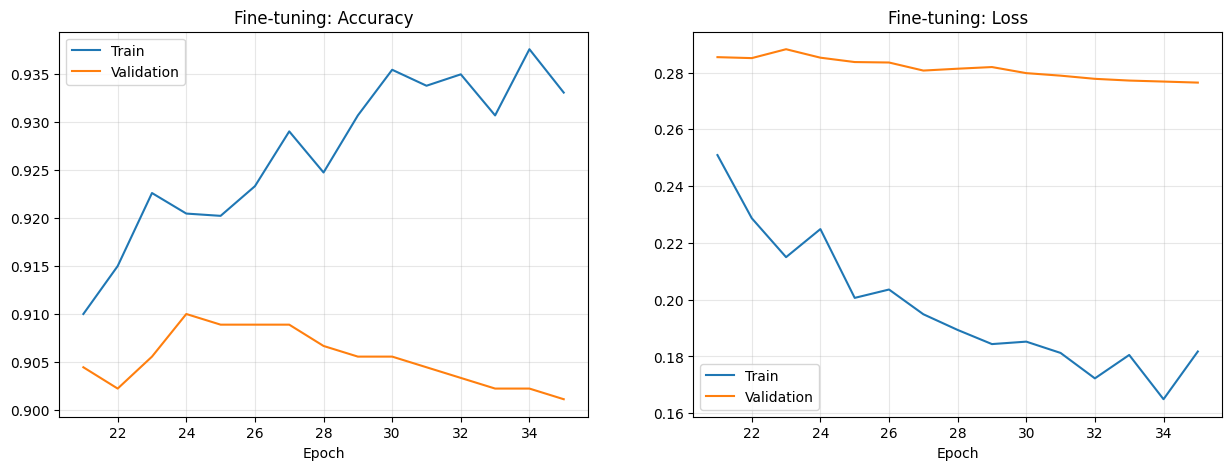

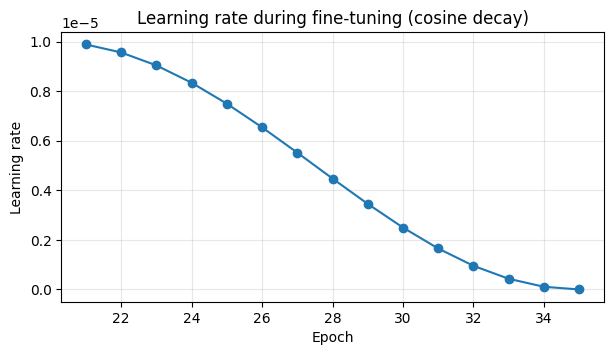

In [26]:
hist_ft = plot_history(history_ft, "Fine-tuning", start_epoch=FROZEN_EPOCHS)

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(FROZEN_EPOCHS + 1, FROZEN_EPOCHS + len(lr_log) + 1), lr_log, marker="o")
plt.title("Learning rate during fine-tuning (cosine decay)")
plt.xlabel("Epoch"); plt.ylabel("Learning rate"); plt.grid(alpha=0.3)
plt.show()

### Fine-tuning round 2: interpretation
- Training accuracy kept rising (0.910 → 0.938) and training loss kept falling (0.25 → about 0.17), but validation accuracy peaked at **0.9100 in the 4th epoch of the round** and then drifted down to 0.901.
- The train–validation gap widened to about 3 points. With 2M trainable parameters and only 4,200 training images, extra fine-tuning mainly improves the fit to the training images, which is a sign of overfitting rather than better generalisation.
- **Takeaway:** a single 15-epoch round was enough; longer fine-tuning gave no meaningful benefit.

### 8.4 Before vs after comparison
Reload the best fine-tuned checkpoint and evaluate it on the validation and test sets. The frozen-base numbers were recorded in Section 8 before any layers were unfrozen. The test set is used here for the first time; no decision in this notebook was based on it.

In [27]:
model.load_weights(FINETUNE_CKPT)
ft_val_loss, ft_val_acc = model.evaluate(val_ds, verbose=0)
ft_test_loss, ft_test_acc = model.evaluate(test_ds, verbose=0)

comparison = pd.DataFrame({
    "Frozen Base":       [frozen_val_acc, frozen_val_loss, frozen_test_acc, frozen_trainable],
    "After Fine-Tuning": [ft_val_acc, ft_val_loss, ft_test_acc, ft_trainable],
}, index=["Validation Accuracy", "Validation Loss", "Test Accuracy", "Trainable Params"])

comparison.style.format("{:.4f}", subset=pd.IndexSlice[["Validation Accuracy", "Validation Loss", "Test Accuracy"], :]) \
               .format("{:,.0f}", subset=pd.IndexSlice[["Trainable Params"], :])

,Frozen Base,After Fine-Tuning
Validation Accuracy,0.9022,0.9100
Validation Loss,0.2691,0.2852
Test Accuracy,0.9122,0.9078
Trainable Params,"164,742","2,026,182"


**Discussion.** Fine-tuning changed results only marginally. Validation accuracy rose from 0.9022 to 0.9100 (+0.8 points, about 7 images out of 900), validation loss rose slightly (0.2691 → 0.2852), and test accuracy fell from 0.9122 to 0.9078 (−0.4 points, about 4 images out of 900). For an accuracy of about 90% measured on 900 images, the standard error is about ±1 point, so all these differences are within noise: **fine-tuning did not meaningfully improve this model**, despite 12× more trainable parameters. Part 4 shows why: most of the remaining errors come from genuinely ambiguous classes rather than from weak features.

# Part 4 — Evaluation & Analysis

## 9. Evaluation & Error Analysis
Evaluate the best fine-tuned model on the 900 held-out test images: per-class metrics, confusion matrix, and a visual inspection of misclassified images. `get_predictions` collects the images, true labels and predicted probabilities in one pass; because the test set is not shuffled, they line up one-to-one.

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

def get_predictions(model, dataset):
    """Return true labels, predicted labels, probabilities and images for a non-shuffled dataset."""
    images = np.concatenate([x.numpy().astype("uint8") for x, _ in dataset])
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    y_prob = model.predict(dataset, verbose=0)
    return y_true, y_prob.argmax(axis=1), y_prob, images

y_true, y_pred, y_prob, test_images = get_predictions(model, test_ds)
print(f"Test images: {len(y_true)} | misclassified: {(y_true != y_pred).sum()}")

Test images: 900 | misclassified: 83


### 9.1 Classification report
Per-class **precision** (when the model predicts a class, how often it is right), **recall** (of all images of a class, how many the model finds) and **F1** (the harmonic mean of the two). The two lowest F1 scores identify the hardest classes.

In [30]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

report_df = pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names,
                                               output_dict=True)).T.loc[class_names]
print("Two hardest classes (lowest F1):")
print(report_df["f1-score"].sort_values().head(2).round(3))

              precision    recall  f1-score   support

   buildings      0.909     0.933     0.921       150
      forest      0.980     0.987     0.983       150
     glacier      0.861     0.787     0.822       150
    mountain      0.830     0.847     0.838       150
         sea      0.936     0.980     0.958       150
      street      0.926     0.913     0.919       150

    accuracy                          0.908       900
   macro avg      0.907     0.908     0.907       900
weighted avg      0.907     0.908     0.907       900

Two hardest classes (lowest F1):
glacier     0.822
mountain    0.838
Name: f1-score, dtype: float64


**Per-class analysis.** Overall test accuracy is **90.8%** (83 errors out of 900). Forest is the easiest class (F1 0.983, only 2 errors), consistent with its distinctive dark-green colour profile in the EDA, followed by sea (F1 0.958, recall 0.980). The two hardest classes are **glacier (F1 0.822)** and **mountain (F1 0.838)**.

**Hypothesis:** both classes contain the same visual ingredients (snow, ice, rock and sky), and glaciers almost always appear surrounded by mountains, so the deciding factor is often a matter of proportion rather than presence. Glacier has the lowest recall (0.787): the model misses about one glacier in five, mostly labelling it as mountain. Mountain has the lowest precision (0.830): about one in six "mountain" predictions is actually a glacier. Buildings and street sit in the middle (F1 ≈ 0.92), confused mainly with each other.

### 9.2 Confusion matrix
Rows are true classes and columns are predicted classes; the diagonal holds correct predictions. Setting the diagonal to zero leaves only the mistakes, which are then ranked to find the most common misclassification pairs.

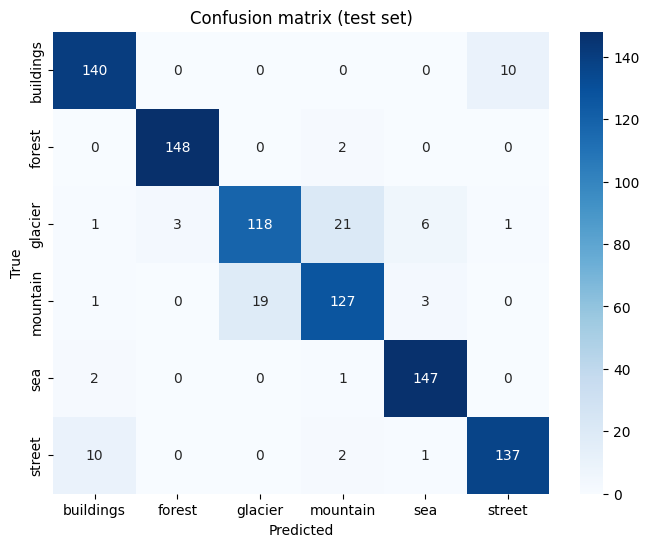

Most common misclassifications (count, true → predicted):
   21  glacier → mountain
   19  mountain → glacier
   10  street → buildings
   10  buildings → street
    6  glacier → sea


In [31]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)")
plt.show()

errors = cm.copy()
np.fill_diagonal(errors, 0)                       # ignore correct predictions
pairs = sorted(((errors[i, j], class_names[i], class_names[j])
                for i in range(len(class_names)) for j in range(len(class_names))
                if errors[i, j] > 0), reverse=True)
print("Most common misclassifications (count, true → predicted):")
for count, t, p in pairs[:5]:
    print(f"  {count:>3}  {t} → {p}")

**Confusion matrix analysis.** The most common misclassification is **glacier → mountain (21 images)**, closely followed by **mountain → glacier (19)**. Together they account for 40 of the 83 errors (48%). Buildings ↔ street (10 in each direction) adds another 20, so **72% of all errors come from two pairs of related classes**, exactly the two pairs I predicted from the sample grid in Section 3. The smaller glacier → sea confusion (6) matches the average-image analysis, where glacier and sea had the most similar overall colour and layout. Forest and sea are almost never confused with anything (2 and 3 errors respectively).

### 9.3 Error analysis
A random sample of 15 misclassified test images, each shown with its true label, predicted label and the model's confidence in its prediction.

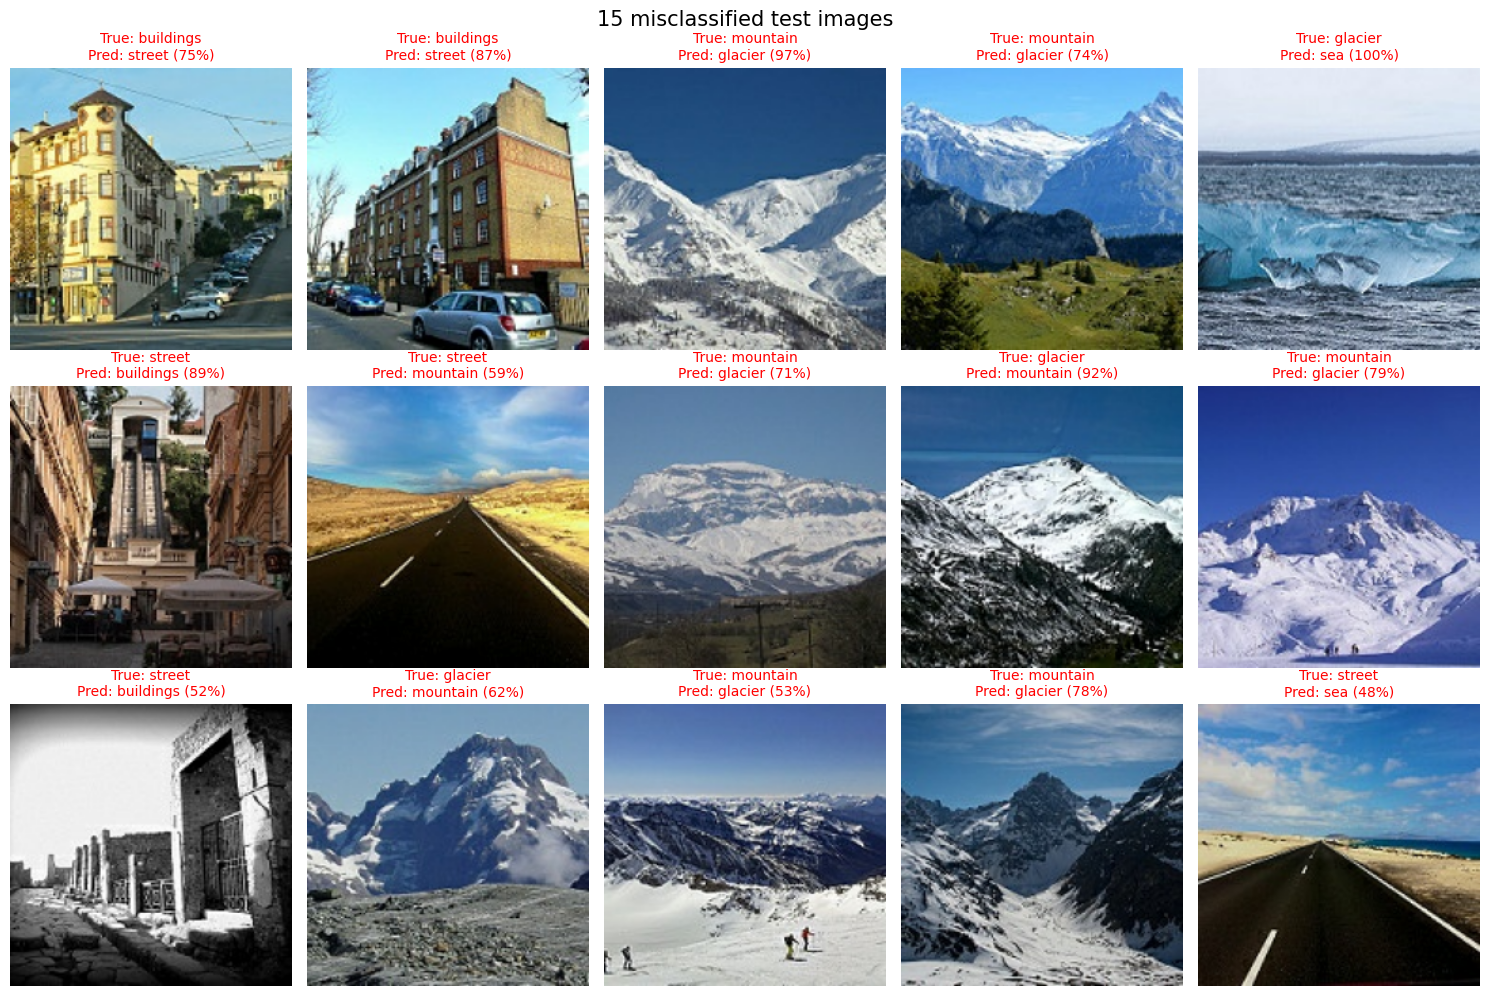

In [32]:
def show_misclassified(images, y_true, y_pred, y_prob, class_names, n=15, seed=SEED):
    """Display a random sample of misclassified images with true/predicted labels and confidence."""
    wrong = np.where(y_true != y_pred)[0]
    picks = np.random.default_rng(seed).choice(wrong, size=min(n, len(wrong)), replace=False)
    cols = 5
    rows = int(np.ceil(len(picks) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.4 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, picks):
        ax.imshow(images[idx])
        ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} "
                     f"({y_prob[idx].max():.0%})", color="red", fontsize=10)
    plt.suptitle(f"{len(picks)} misclassified test images", fontsize=15)
    plt.tight_layout()
    plt.show()

show_misclassified(test_images, y_true, y_pred, y_prob, class_names)

**Error patterns.** The errors are **systematic, not random**. All 15 sampled errors fall into four patterns:

1. **Snowy peaks, mountain ↔ glacier (8 of 15):** several are predicted with high confidence (92%, 97%). These photos contain both mountains and glacial snow or ice, so the dataset label reflects one annotator's judgement about which dominates. Confident errors on such images point to **label ambiguity** rather than model failure.
2. **Street-level buildings, buildings ↔ street (4 of 15):** facades photographed from the pavement with parked cars and road in view (buildings → street at 75% and 87%), or a narrow street dominated by one facade (street → buildings at 89%). These are reasonable examples of both classes.
3. **Streets without buildings (2 of 15):** an empty desert road predicted as mountain (59%) and a road running to a flat horizon predicted as sea (48%). The low confidence shows the model was genuinely unsure. It appears to have learned "street = road + buildings on both sides", so a road through open landscape breaks that concept.
4. **Ice in water (1 of 15):** a glacier image showing ice chunks floating in the sea was predicted as sea with 100% confidence; arguably this photo fits *sea* as well as *glacier*.

### 9.4 Performance commentary
I expected fine-tuning to add a few percentage points, but the gain was negligible (+0.8 points validation, −0.4 points test, both within noise). I see three reasons. First, the frozen ImageNet features were already excellent for this task: about 90% accuracy while training only 7% of the parameters, with validation accuracy near its final level after a single epoch. Second, the remaining errors are concentrated in ambiguous class pairs where even a human would hesitate, which places a ceiling on accuracy that better features cannot remove. Third, with 2M trainable parameters and 4,200 images, fine-tuning quickly started to overfit: in the second round, training accuracy reached 0.94 while validation accuracy stayed at about 0.90. In hindsight, using more of the 17,000 available images, or cleaning ambiguous labels, would likely help more than further fine-tuning.

# Part 5 — Reflection

## 10. Reflections

### Q7. Dataset choice
I chose the Intel Image Classification dataset because it has six balanced, real-world scene classes with far more than the required 200 images per class, and it is unrelated to the food dataset used in class. It relates to practical applications such as automatic photo tagging, location-based image search and environmental monitoring from drone or aerial imagery. Imbalance was not a challenge: the ratio between the largest and smallest class was only 1.16, and sampling 1,000 images per class made the working dataset perfectly balanced. The main challenges were low resolution (images are 150×150 and had to be upscaled to MobileNetV2's 224×224, which adds pixels but no detail) and label ambiguity, since many photos contain several classes at once, such as glaciers within mountain ranges or buildings along streets. The EDA made this visible early: the sample grid already showed questionable labels, and the same class pairs ended up causing 72% of the test errors.

### Q8. Architecture choice
I chose MobileNetV2 after comparing the four allowed architectures by parameter count and ImageNet accuracy. VGG16 has about 40× more parameters than MobileNetV2 (138M vs 3.5M) for the same 71.3% ImageNet accuracy, so its extra size offers no benefit. EfficientNetB0 (77.1%) and ResNet50 (74.9%) are more accurate on ImageNet, but they are larger or deeper and slower to train. With only 4,200 training images, a smaller model also has fewer weights to adapt during fine-tuning, which lowers the risk of overfitting. The trade-off was accepting a few points of ImageNet accuracy in exchange for speed and simplicity, which let me run, debug and re-run experiments within a free Colab session. Since the frozen model already reached about 90% accuracy, and fine-tuning showed the remaining errors are mostly due to ambiguous labels, the smaller architecture was clearly sufficient for this task.

### Q9. Transfer learning insights
I was surprised by how quickly and how well the frozen base worked: validation accuracy was 0.888 after a single epoch, and training only 165,000 parameters (7% of the model) reached 0.90. Even my broken first run, which accidentally trained on a single batch of 32 images, reached 80% validation accuracy, which shows how much useful information is already contained in the pretrained features. ImageNet pretraining generalised well to my domain, likely because ImageNet includes landscape-like classes (such as alps, seashores and valleys) and because low-level features like edges and textures are universal. The colour histograms showed that buildings and street have almost identical colour profiles, yet the model separated them well (F1 ≈ 0.92), so it relies on learned structure and shape rather than colour. The pretrained features were weakest on the glacier/mountain distinction, which depends on subtle differences in the proportion of snow, ice and rock.

### Q10. Fine-tuning decisions
I unfroze from layer 100 (`block_11_expand_relu`) onward, 54 of 154 layers, because later layers hold the most ImageNet-specific features while early layers hold generic edges and textures worth keeping. I chose slightly more layers than the class example (from 120), because scenes differ more from ImageNet objects than food does, but not the whole network, because the dataset is small. I used a learning rate 100× smaller (1e-5) to avoid overwriting good pretrained weights, plus cosine decay to make the steps even smaller towards the end. When fine-tuning started, training accuracy dropped sharply (0.93 → 0.79) and validation loss rose slightly for a few epochs, but validation accuracy stayed at about 0.90 and the loss recovered as the learning rate decayed, so training remained stable overall. A second round of fine-tuning raised training accuracy to 0.94 while validation accuracy stayed at about 0.90–0.91, showing that more fine-tuning led to overfitting rather than better generalisation. I also learned that the model must be recompiled after unfreezing, otherwise the optimizer keeps updating only the head.

### Q11. What I would do next
With more time and compute, I would first train on the full dataset (about 17,000 images instead of 6,000), since overfitting during fine-tuning suggests that the amount of data was the limiting factor. I would use Grad-CAM to see which image regions drive the predictions, for example whether "street" predictions depend on buildings rather than the road, which would explain the errors on empty rural roads. I would also review the glacier and mountain labels, since many confident errors may be mislabelled or genuinely contain both classes; a multi-label approach might suit this data better. I would compare EfficientNetB0, which is more accurate on ImageNet, and test unfreezing fewer layers with early stopping. Finally, repeating each experiment with several random seeds would show whether the small differences between the frozen and fine-tuned models are real or just noise.

## 11. Summary & Conclusion

### What was built
This notebook adapts a pretrained **MobileNetV2** to classify six natural and urban scene types (buildings, forest, glacier, mountain, sea, street) from the **Intel Image Classification** dataset. The full transfer-learning pipeline was implemented:

1. **Data preparation:** 1,000 images per class were sampled from the 17,034 available and split 70/15/15 per class into separate folders (4,200 / 900 / 900), so that no image appears in more than one split.
2. **Exploratory analysis:** a sample grid, class distribution, average image per class and colour histograms, used to predict which classes would be hardest before any model was trained.
3. **Frozen-base training:** MobileNetV2 was loaded without its top layer and frozen, and a custom head (GAP → Dropout → Dense(128) → Dropout → Softmax) was trained for 20 epochs with realistic augmentations (horizontal flip, small rotation, zoom, brightness).
4. **Fine-tuning:** the top 54 layers were unfrozen (164,742 → 2,026,182 trainable parameters) and trained at a 100× smaller learning rate with cosine decay, in two rounds of 15 epochs.
5. **Evaluation:** a classification report, confusion matrix and visual error analysis on the held-out test set.

### Results
| Metric | Frozen Base | After Fine-Tuning |
|---|---|---|
| Validation Accuracy | 0.9022 | 0.9100 |
| Validation Loss | 0.2691 | 0.2852 |
| Test Accuracy | 0.9122 | 0.9078 |
| Trainable Params | 164,742 | 2,026,182 |

### Key findings
- **Transfer learning works remarkably well here:** training only 7% of the parameters reached about 90% accuracy, so ImageNet features generalise strongly to scene images.
- **Fine-tuning gave no meaningful improvement:** the differences fall within run-to-run noise, and a second round raised training accuracy to 0.94 while validation accuracy stayed at about 0.90, a clear sign of overfitting on a small dataset.
- **The EDA predictions were confirmed:** glacier ↔ mountain (40 errors) and buildings ↔ street (20 errors) account for **72% of all test errors**, and forest is the easiest class (F1 0.983).
- **The errors are systematic, not random:** most come from genuinely ambiguous images (snowy peaks that are both glacier and mountain) or from images that break a learned pattern (streets without buildings).

### Lessons learned
- **Inspect data before modelling:** the average images and histograms predicted the confusion matrix before any training happened.
- **Verify the pipeline, not just the score:** a first run that looked plausible (80% validation accuracy) was silently training on a single batch per epoch, caught only by noticing that training accuracy moved in steps of 1/32.
- **More capacity is not always better:** with strong pretrained features and ambiguous labels, the limiting factor was data quality and quantity, not the number of trainable parameters.

### Conclusion
A frozen MobileNetV2 with a small custom head classifies six scene types with about 91% test accuracy, and fine-tuning confirmed that the pretrained features were already close to what this dataset allows. The most promising next steps are more training data, cleaner or multi-label annotations for ambiguous scenes, and Grad-CAM analysis to verify what the model is actually looking at.

## AI Assistance Declaration
I used Claude (Anthropic) as a tutor throughout this assignment. It explained each concept step by step (transfer learning, freezing, augmentation choices, learning-rate schedules and evaluation metrics), provided the code, which I ran and checked section by section in Colab, and drafted most of the written explanations and reflections from my actual results, which I reviewed. It also helped me debug a silent data-pipeline bug: my first training run used only one batch per epoch because of a partially filled cache, which we identified from training accuracy changing in steps of 1/32. The key things I learned were why the base is frozen before fine-tuning, why fine-tuning needs a much smaller learning rate and a recompile, why augmentations must keep images realistic (no vertical flips for scenes), why splitting must happen at the file level to avoid leakage between validation and test sets, and why a plausible-looking score still needs its pipeline verified.